In [1]:
# imports
import pandas as pd
import numpy as np
import pathlib

import sklearn.preprocessing as preprocessing
from sklearn import linear_model, metrics, model_selection
from sklearn.model_selection import train_test_split

import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns; sns.set_theme(style='ticks', context='talk')

#import colorcet as cc


In [2]:
#experiment name
experiment = '251017AKDER011'

#define save bool
save = True

#define paths
save_path = pathlib.Path(r'..\processed_data')

#define task
task_df = pd.read_csv('Mackey-Glass.csv', index_col='time (s)', usecols = ['time (s)', 'y value'])

#define data path
preprocessed_data = pd.read_csv(r'..\data\mackey_glass_single_and_series_preprocessed_data.csv', index_col=0)

colours = ['#069DC7','#A02B93', '#FFC000']
alphas = [1, 0.8]

In [3]:
def plot_func(task, axes, data_df, alpha, steps_ahead, colour, save = save, save_path = save_path):

    #plot sine wave
    sns.lineplot(x = task.index/60, y = task['y value'], color = 'k', ax=axes[0], alpha = 0.7, linestyle = '--')

    #plot prediciton on first axis
    sns.lineplot(data = data_df, x = data_df['forecast time (s)']/60, y = data_df['y predict'], 
                #hue = 'dataset', 
                style = data_df['dataset'],
                color = colour,
                markers=False, dashes = False,ax=axes[0], legend = False,
                alpha = alpha,
                lw = 3)
    
    #plot ASE on second axis
    sns.lineplot(x = data_df['forecast time (s)']/60, y = data_df['ase'], 
                #hue = 'dataset', 
                color = colour,
                style = data_df['dataset'], markers=False, dashes = False,ax=axes[1], legend = False,
                alpha = alpha,
                lw = 3)

    #set title
    axes[0].set_title(f"Mackey-Glass prediction {steps_ahead*4.5} mins ahead")

    #set axes label
    axes[0].set_xlabel(r"")
    axes[1].set_xlabel(r"Time (min)")
    #def axis limits
    axes[1].set_ylim(0,2)
    axes[0].set_xlim(0,800)
    axes[1].set_xlim(0,800)

    #include horizontal line at 1 for ASE
    axes[1].axhline(y=1, color='gray', linestyle='--', linewidth=1)
    sns.despine()

    #vlines for train test split
    axes[0].vlines(x = (data_df.index[data_df['dataset'] == 'test'][0] + (steps_ahead-1))* 4.5, ymin = 0.4, ymax = 1.4, color = colour, alpha = 0.5, linestyle = '--', )
    axes[1].vlines(x = (data_df.index[data_df['dataset'] == 'test'][0] + (steps_ahead-1))* 4.5, ymin = 0, ymax = 1, color = colour, alpha = 0.5, linestyle = '--', )
    
    axes[1].set_ylabel("ASE")
    if save:
        plt.savefig(save_path/f"mackey_glass_single_and_series_{steps_ahead*4.5}min_plot.svg", dpi = 900)

In [4]:
def task_prediction(df, task_df, predict_ahead = 1, save = save):
    #create values to shift by (must be inverse for steps ahead)
    shift_value = -predict_ahead

    #define model and regularisation (sigma value)
    reg = linear_model.RidgeCV()
        
    #empty dict for mse values
    ase_dict = {}

    #empty df to store predictions
    prediction_df = pd.DataFrame()

    #empty df to iteratively store dataset for augmentation
    group_data_ff = pd.DataFrame()

    #define figure parameters
    fig1, axes = plt.subplots(2,1,figsize=(15,6), constrained_layout=True, gridspec_kw={'height_ratios': [5, 1]})
    n=0
    #iterate over the final datased groupwise by sample conditions to train and score
    for name, group in df.groupby('Reactor'):

        # Define which columns are parameter columns
        para_columns = ['time (s)', 'y value', 'Reactor', 'sample no.']

        group_para = group[para_columns].reset_index(drop = True)

        # Separate data column labels into a list
        data_columns = [col for col in group.columns if col not in para_columns]
        
        #generate new column labels with RX and store in a dict
        labels_ff = {label: f'{label}_{name}' for label in data_columns}

        #create a df of only data, rename the columns, reset the index and combine previous dfs 
        group_data = group[data_columns].rename(labels_ff, axis = 1).reset_index(drop=True)
        group_data_ff = pd.concat([group_data_ff, group_data], axis = 1)
        group_ff = pd.concat([group_para, group_data_ff], axis = 1)

        #shift values to define predictions
        group_ff['y forecast'] = group_ff['y value'].shift(shift_value)

        #define column for time ahead to make plotting easier
        group_ff['forecast time (s)'] = group_ff['time (s)'].shift(shift_value)

        #replace na values
        group_nona = group_ff.fillna(0).copy()
        
        #define label and x values
        U = group_nona['forecast time (s)'].values
        X = group_nona.drop(['time (s)', 'y value', 'Reactor', 'sample no.', 'y forecast', 'forecast time (s)'], axis = 1).values
        X = preprocessing.StandardScaler().fit_transform(X)

        y_index = group_nona['y forecast'].values

        # Train/test split
        U_train, U_test, X_train, X_test, y_train, y_test = train_test_split(U, X, y_index, train_size=0.8, shuffle=False)
        
        # Train model
        reg.fit(X_train, y_train)

        #predict test set
        y_train_pred = reg.predict(X_train)
        y_train_pred = pd.DataFrame(y_train_pred, columns = ['y predict'])
        y_train_pred['forecast time (s)'] = U_train
        y_train_pred['dataset'] = 'train'

        #predict train set
        y_test_pred = reg.predict(X_test)
        y_test_pred = pd.DataFrame(y_test_pred, columns = ['y predict'])
        y_test_pred['forecast time (s)'] = U_test
        y_test_pred['dataset'] = 'test'

        #combine prediction sets, set index to prediction time and join with data df
        predictions = pd.concat([y_train_pred, y_test_pred], axis = 0)
        predictions = predictions.set_index('forecast time (s)')
        group_fin = group_ff.join(predictions, on = 'forecast time (s)')

        #calculate absolute error
        group_fin['difference'] = abs(group_fin['y forecast'] - group_fin['y predict'])

        #calculate ase
        standard_dev_train = np.std(y_train)
        group_fin['ase'] = np.abs(group_fin['difference']/ standard_dev_train)

        #calculate mase for test set of each group
        ase = group_fin.loc[group_fin['dataset'] =='test', 'ase'].mean()
        
        #append ase dict with values per group
        ase_dict[name] = ase

        # Append results to df for plotting
        prediction_df = pd.concat([prediction_df, group_fin])

        #plot predictions
        plot_func(task_df, axes, group_fin, alpha = alphas[n], steps_ahead = predict_ahead, colour = colours[n], save = save)
        n+=1
        
    plt.show()        
    if save:
        prediction_df.to_csv(save_path/f'mackey_glass_single_and_series_{predict_ahead*4.5}min_prediction.csv')

    return prediction_df, ase_dict


C:\Users\annac\AppData\Local\Temp\ipykernel_29088\2867791254.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  group_ff['y forecast'] = group_ff['y value'].shift(shift_value)
C:\Users\annac\AppData\Local\Temp\ipykernel_29088\2867791254.py:43: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  group_ff['forecast time (s)'] = group_ff['time (s)'].shift(shift_value)
C:\Users\annac\AppData\Local\Temp\ipykernel_29088\2867791254.py:79: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.inse

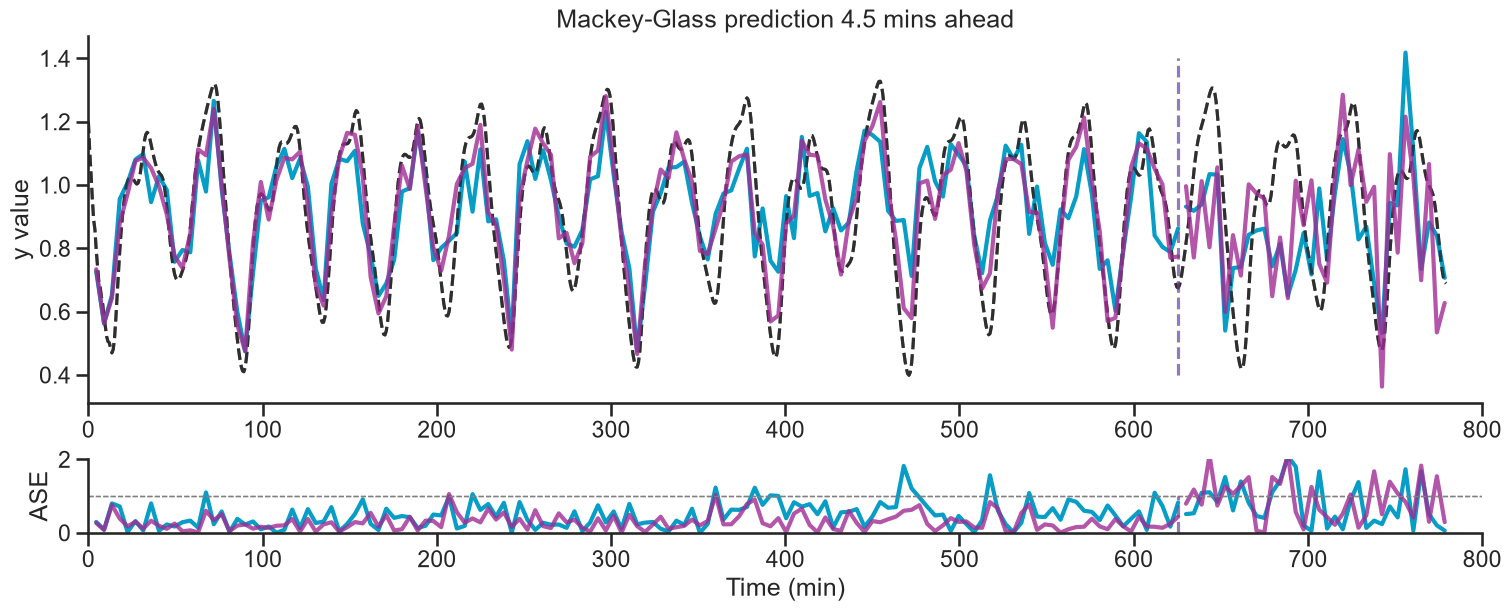

C:\Users\annac\AppData\Local\Temp\ipykernel_29088\2867791254.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  group_ff['y forecast'] = group_ff['y value'].shift(shift_value)
C:\Users\annac\AppData\Local\Temp\ipykernel_29088\2867791254.py:43: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  group_ff['forecast time (s)'] = group_ff['time (s)'].shift(shift_value)
C:\Users\annac\AppData\Local\Temp\ipykernel_29088\2867791254.py:79: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.inse

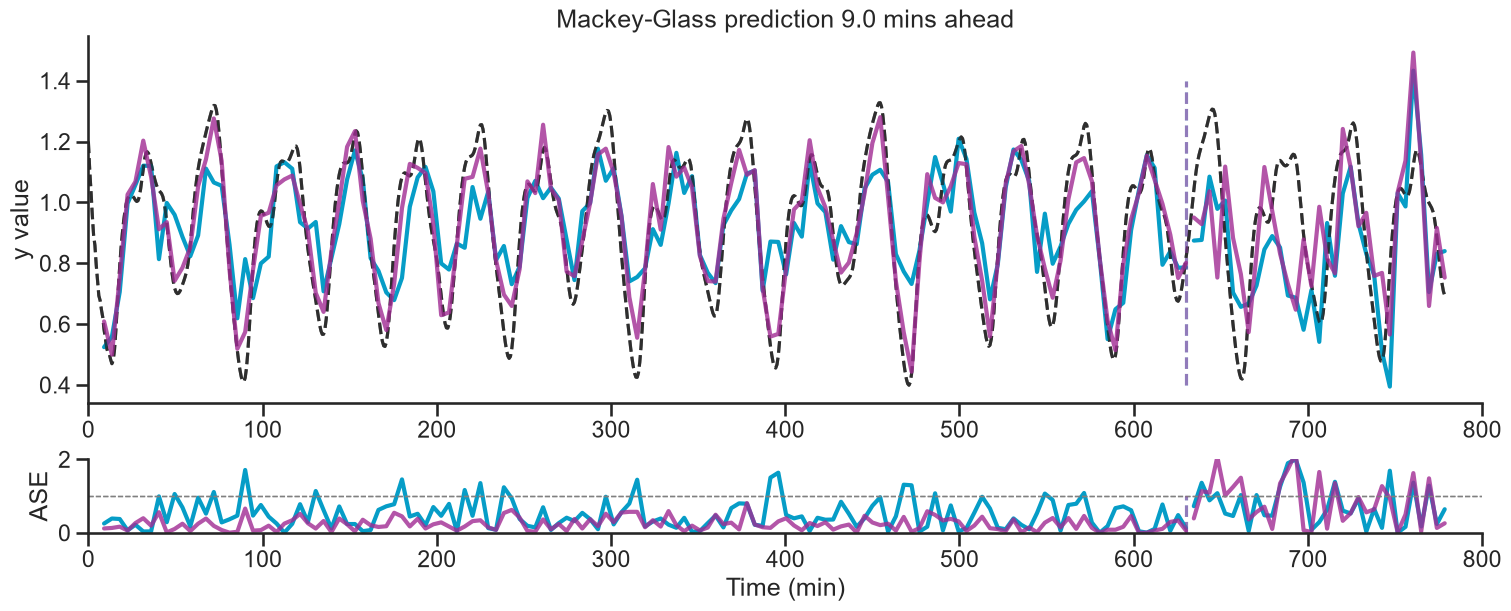

C:\Users\annac\AppData\Local\Temp\ipykernel_29088\2867791254.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  group_ff['y forecast'] = group_ff['y value'].shift(shift_value)
C:\Users\annac\AppData\Local\Temp\ipykernel_29088\2867791254.py:43: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  group_ff['forecast time (s)'] = group_ff['time (s)'].shift(shift_value)
C:\Users\annac\AppData\Local\Temp\ipykernel_29088\2867791254.py:79: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.inse

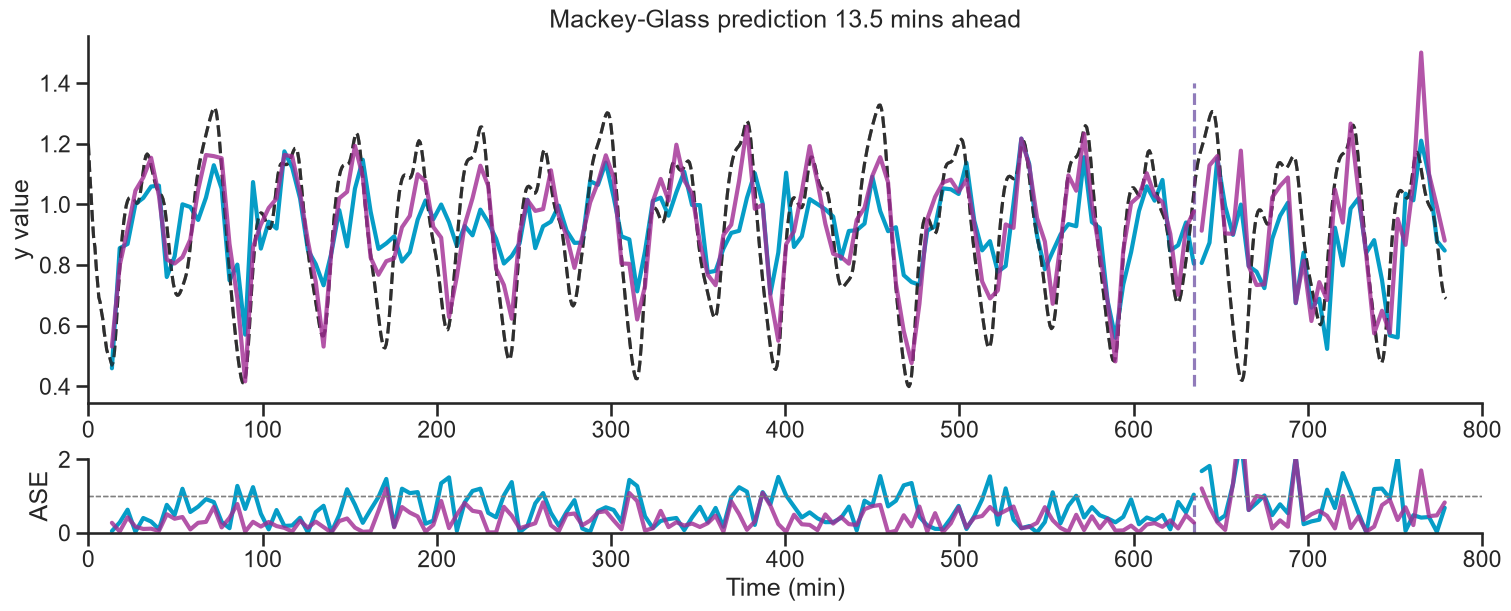

C:\Users\annac\AppData\Local\Temp\ipykernel_29088\2867791254.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  group_ff['y forecast'] = group_ff['y value'].shift(shift_value)
C:\Users\annac\AppData\Local\Temp\ipykernel_29088\2867791254.py:43: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  group_ff['forecast time (s)'] = group_ff['time (s)'].shift(shift_value)
C:\Users\annac\AppData\Local\Temp\ipykernel_29088\2867791254.py:79: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.inse

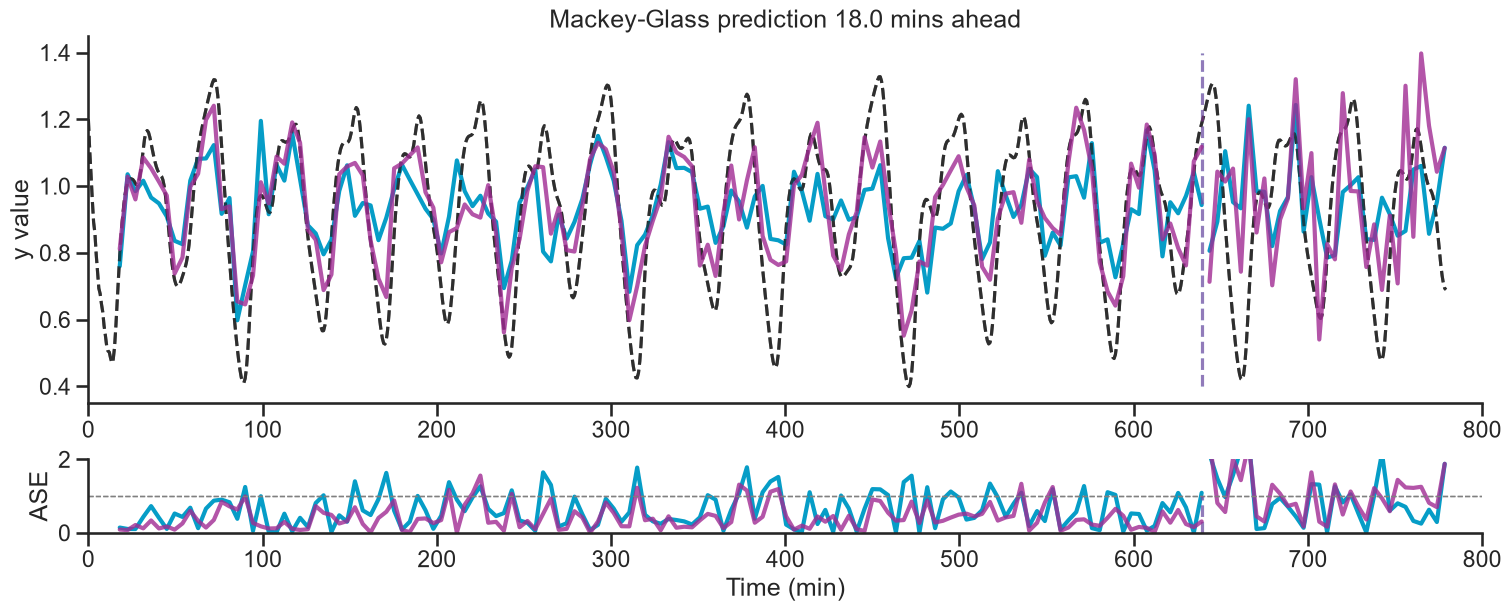

C:\Users\annac\AppData\Local\Temp\ipykernel_29088\2867791254.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  group_ff['y forecast'] = group_ff['y value'].shift(shift_value)
C:\Users\annac\AppData\Local\Temp\ipykernel_29088\2867791254.py:43: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  group_ff['forecast time (s)'] = group_ff['time (s)'].shift(shift_value)
C:\Users\annac\AppData\Local\Temp\ipykernel_29088\2867791254.py:79: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.inse

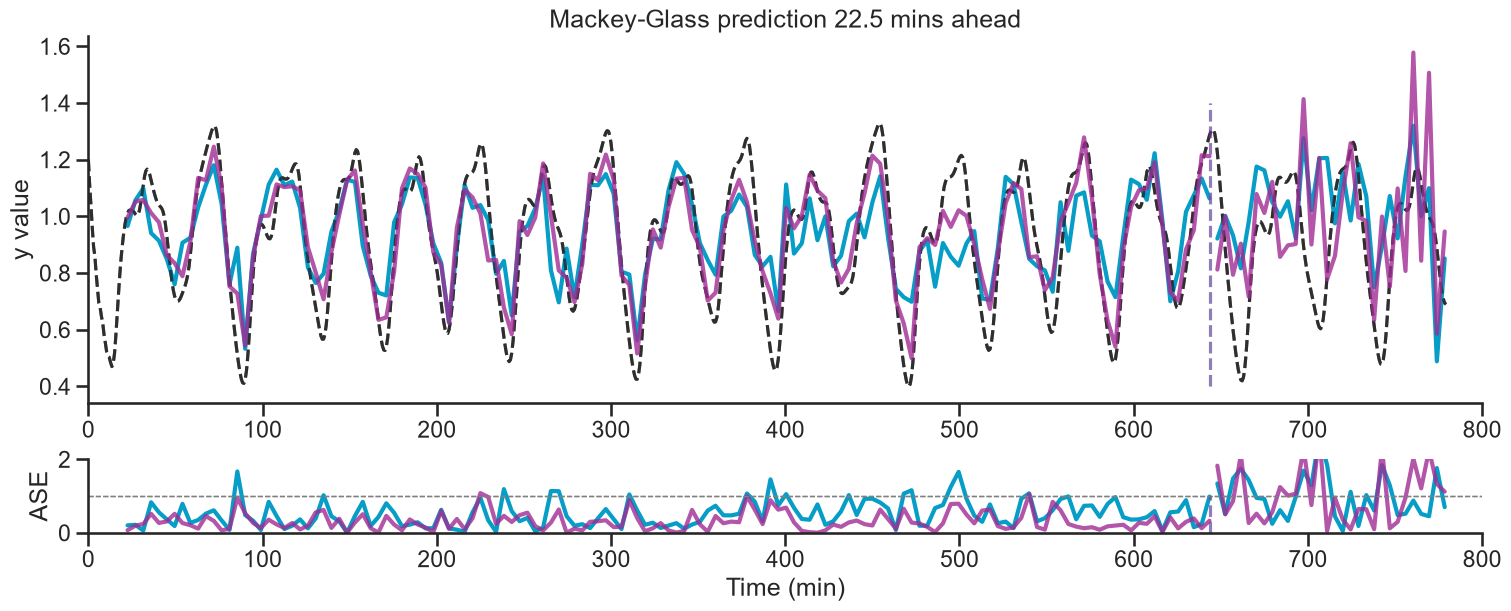

           1         2         3         4         5
R1  0.781827  0.770125  0.874733  0.944641  0.995759
R2  0.910150  0.846290  0.699587  1.033360  1.013616


In [5]:
steps_ahead = [1,
               2,3,4,5
               ]

mase_score = pd.DataFrame()
step_pred_dict = {}

for step in steps_ahead:
    pred_steps, ase_dict = task_prediction(preprocessed_data, task_df = task_df, predict_ahead = step)


    step_pred_dict[f'{step}'] = pred_steps


    mase_score = pd.concat([mase_score, pd.DataFrame.from_dict(ase_dict, orient = 'index', columns = [step])], axis = 1)

print (mase_score)

